# Classification - Ensemble Learning

The following tutorial contains Python examples for solving classification problems. You should refer to the Slides Week 7 to understand some of the concepts introduced in this tutorial. 

Classification is the task of predicting a nominal-valued attribute (known as class label) based on the values of other attributes (known as predictor variables). The goals for this tutorial are as follows:
1. To provide examples of using different ensemble learning techniques from the scikit-learn library package.
2. To make a model performance comparison.

Read the step-by-step instructions below carefully. To execute the code, click on the corresponding cell and press the SHIFT-ENTER keys simultaneously.


# Summary of toolbox

1. training testing data split. from sklearn.model_selection import train_test_split
https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html

2. decision tree. from sklearn.tree import DecisionTreeClassifier
https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html

3. Random Forest. from sklearn.ensemble import RandomForestClassifier
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

4. Bagging. from sklearn.ensemble import BaggingClassifier
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html

5. Adaboosting. from sklearn.ensemble import AdaBoostClassifier
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html

6. StackingClassifier. from sklearn.ensemble import StackingClassifier
https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html

7. confusion matrix. from sklearn.metrics import ConfusionMatrixDisplay
https://scikit-learn.org/stable/auto_examples/model_selection/plot_confusion_matrix.html
    
8. weighted classification. 
weights = {0:10.0, 1:1.0} #the weight put the weight for class "0" to 10 and "1" to 1. So the "0" class is more important
clf = DecisionTreeClassifier(max_depth=2,class_weight=weights)
    

## Hold-out Data preparation

In [1]:
from sklearn.model_selection import train_test_split # this function provides a single "Hold-Out" Validation.
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score #similar to MAE, we use accuracy_score evaluation metric.
import pandas as pd
import numpy as np

data = pd.read_csv('Credit_approval.csv',header='infer')
data.head(5)

,Age,Debt,YearsEmployed,CreditScore,Income,Approved
0,30.83,0.000,1.25,1,0,+
1,58.67,4.460,3.04,6,560,+
2,24.50,0.500,1.50,0,824,+
3,27.83,1.540,3.75,5,3,+
4,20.17,5.625,1.71,0,0,+


In [2]:
Y = data['Approved'] #this is our prediction target
X = data.drop(['Approved'],axis=1)
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.4, random_state=1) 
# From original dataset, 0.4 (40%) is used for testing (validation). random_state ensures random split is fixed.

# <span style="background-color: yellow;">Base Classifiers</span> 
## 1. Decision Tree Classifier

In [3]:
from sklearn.tree import DecisionTreeClassifier
clf = DecisionTreeClassifier(max_depth=2) # number estimators is the key parameter
clf = clf.fit(X_train, Y_train)
Y_predTrain = clf.predict(X_train)
Y_predTest = clf.predict(X_test)

print('Training accuracy is %f' % accuracy_score(Y_train, Y_predTrain))
      
print('Validation accuracy is %f' %accuracy_score(Y_test, Y_predTest))

Training accuracy is 0.751232
Validation accuracy is 0.727941


# <span style="background-color: yellow;">Ensemble Classifiers</span> 
## 1. Random Forest 

In [4]:
from sklearn.ensemble import RandomForestClassifier
np.random.seed(1) #because the model has random sampling, a random seed can ensure repeated results.
clf = RandomForestClassifier(max_depth=2,n_estimators=500)
clf = clf.fit(X_train, Y_train)
Y_predTrain = clf.predict(X_train)
Y_predTest = clf.predict(X_test)

print('Training accuracy is %f' % accuracy_score(Y_train, Y_predTrain))
      
print('Validation accuracy is %f' %accuracy_score(Y_test, Y_predTest))

Training accuracy is 0.780788
Validation accuracy is 0.761029


## 2. Bagging

In [5]:
from sklearn.ensemble import BaggingClassifier
np.random.seed(1)
clf2 = BaggingClassifier(DecisionTreeClassifier(max_depth=2),n_estimators=50) # number estimators is the key parameter
clf2 = clf2.fit(X_train, Y_train)
Y_predTrain = clf2.predict(X_train)
Y_predTest = clf2.predict(X_test)

print('Training accuracy is %f' % accuracy_score(Y_train, Y_predTrain))
      
print('Validation accuracy is %f' %accuracy_score(Y_test, Y_predTest))

Training accuracy is 0.778325
Validation accuracy is 0.735294


## 3. AdaBoost

In [6]:
from sklearn.ensemble import AdaBoostClassifier
np.random.seed(1)
clf3 = AdaBoostClassifier(DecisionTreeClassifier(max_depth=2),n_estimators=5) # number estimators is the key parameter
clf3 = clf3.fit(X_train, Y_train)
Y_predTrain = clf3.predict(X_train)
Y_predTest = clf3.predict(X_test)

print('Training accuracy is %f' % accuracy_score(Y_train, Y_predTrain))
      
print('Validation accuracy is %f' %accuracy_score(Y_test, Y_predTest))

Training accuracy is 0.770936
Validation accuracy is 0.764706


## 4. StackingClassifier

In [7]:
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score
import numpy as np

np.random.seed(1)

# ---- level-1 base estimators ----
base_estimators = [
    ("dt",  DecisionTreeClassifier(max_depth=3, random_state=1)),
    ("knn", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=7))),
    ("svm", make_pipeline(StandardScaler(), SVC(probability=True, C=1.0, kernel="rbf", random_state=1))),
]

# ---- level-2 meta estimator ----
meta_estimator = LogisticRegression(max_iter=2000, random_state=1)

clf_stack = StackingClassifier(
    estimators=base_estimators,
    final_estimator=meta_estimator,
    cv=5,                # fold number
    stack_method="auto", # automatically select predict_proba / decision_function
    passthrough=False    # pass original features to level 2, can be set as True
)

# training
clf_stack.fit(X_train, Y_train)

# prediction
Y_predTrain = clf_stack.predict(X_train)
Y_predTest  = clf_stack.predict(X_test)

print('Training accuracy is %f'   % accuracy_score(Y_train, Y_predTrain))
print('Validation accuracy is %f' % accuracy_score(Y_test,  Y_predTest))

Training accuracy is 0.805419
Validation accuracy is 0.764706


# <span style="background-color: pink;">Model Comparision</span> 

[[ 70  47]
 [ 18 137]]


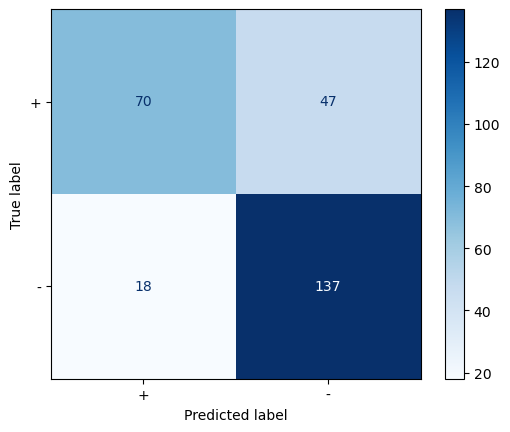

In [8]:
from sklearn.metrics import ConfusionMatrixDisplay
import numpy as np
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, Y_test,display_labels=['+','-'],values_format = '.0f',cmap=plt.cm.Blues)
np.set_printoptions(precision=1)
print(disp.confusion_matrix)

# <span style="background-color: yellow;">Class-weight method for imbalanced classification</span> 

Counter({np.int64(1): 9000, np.int64(0): 1000})


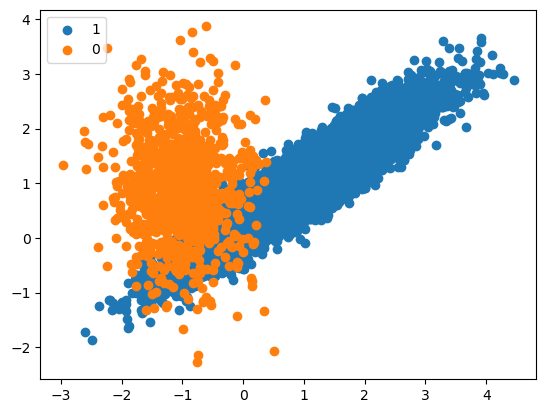

In [9]:
from sklearn.datasets import make_classification
from matplotlib import pyplot
from numpy import where
# Generate and plot a synthetic imbalanced classification dataset
from collections import Counter
# define dataset
np.random.seed(1)
X, y = make_classification(n_samples=10000, n_features=2, n_redundant=0,
                           n_clusters_per_class=1, weights=[0.1], flip_y=0, random_state=2) 
#randomly generate an imbalanced 2-dimensional binary set

counter = Counter(y)
print(counter) #count how many 1 and how many 0

for label, _ in counter.items():
    row_ix = where(y == label)[0]
    pyplot.scatter(X[row_ix, 0], X[row_ix, 1], label=str(label))
pyplot.legend()
pyplot.show()

X_train, X_test, Y_train, Y_test = train_test_split(X, y, test_size=0.4, random_state=1) 

[[ 262  124]
 [   8 3606]]


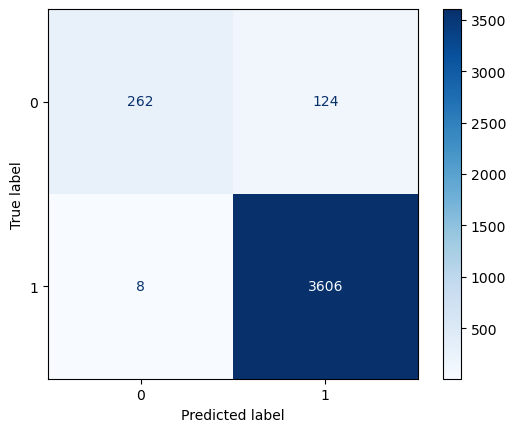

In [10]:
clf=DecisionTreeClassifier(max_depth=2)
clf = clf.fit(X_train, Y_train)
Y_predTrain = clf.predict(X_train)
Y_predTest = clf.predict(X_test)
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, Y_test,display_labels=['0','1'],values_format = '.0f',cmap=plt.cm.Blues)
np.set_printoptions(precision=1)
print(disp.confusion_matrix) #direct implementation. the number of 0 labels that were misclassified as 1 is high

[[ 376   10]
 [ 532 3082]]


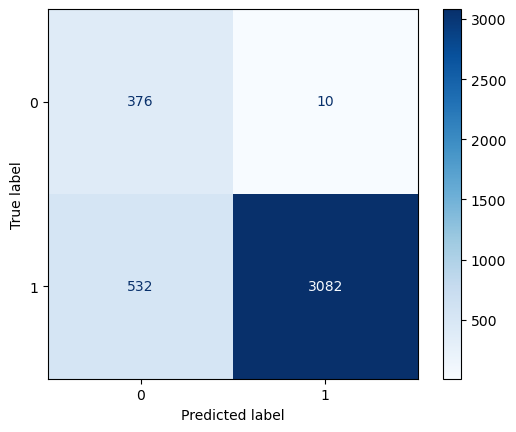

In [11]:
weights = {0:10.0, 1:1.0} #the weight put the weight for class "0" to 10 and "1" to 1. So the "0" class is more important
clf = DecisionTreeClassifier(max_depth=2,class_weight=weights)
clf = clf.fit(X_train, Y_train)
Y_predTrain = clf.predict(X_train)
Y_predTest = clf.predict(X_test)
disp = ConfusionMatrixDisplay.from_estimator(clf, X_test, Y_test,display_labels=['0','1'],values_format = '.0f',cmap=plt.cm.Blues)
np.set_printoptions(precision=1)
print(disp.confusion_matrix)

## Summary

### 1. Learn how to build Ensemble Learning Methods
### 2. Learn how to import different classfiers. Please go to the Sklearn website for more details if you want to study more. https://scikit-learn.org/stable/auto_examples/index.html#classification
### 3. Learn how to compute the confusion matrix
### 4. Learn how to compute the class-sensitive classification

# Week 7 Assignment

### 1.  Use the credictcard-reduced.csv dataset and build Five classification models. Please plot confusion matrix, and evaluate your model performance using accuracy, precision, recall, F-score (50 points). A list of classification models can be found [here](https://scikit-learn.org/stable/auto_examples/classification/plot_classifier_comparison.html)

### 2.  Illustrate the differences between these classifiers and compare the model performances. (30 points)

### 3.  Use the class-weight method from the tutorial for imbalanced classification on the creditcard-reduced.csv dataset. Build a classifier with and without class_weight, then evaluate model performance before and after applying class weights using accuracy, precision, recall, F-score, and confusion matrix.(20 points)